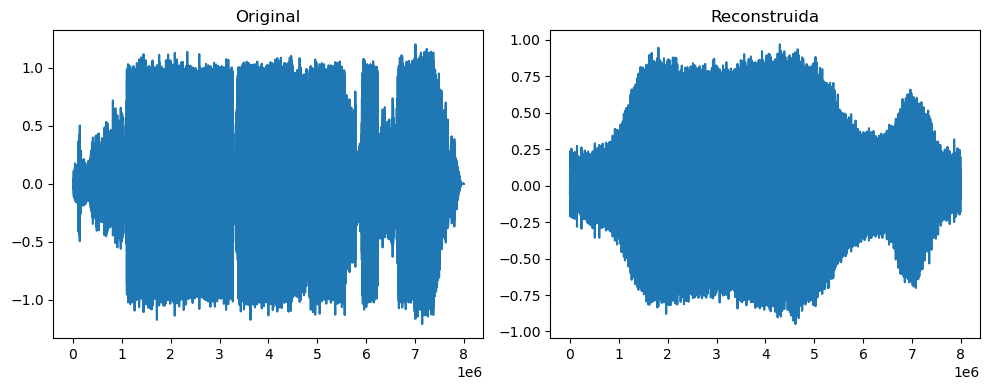

In [1]:
import numpy as np
import librosa
import matplotlib.pyplot as plt

# Cargar un archivo de audio
audio_path = 'audio_muestra.mp3'
y, sr = librosa.load(audio_path, sr=None, mono=True)

# Transformada de Fourier
Y = np.fft.fft(y)

# Umbralización (ejemplo: mantener 10% de las componentes de frecuencia mayores)
threshold = 0.1 * np.max(np.abs(Y))
Y[np.abs(Y) < threshold] = 0

# Transformada Inversa de Fourier
y_reconstructed = np.fft.ifft(Y).real

# Comparar la señal original y reconstruida
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(y)
plt.title('Original')
plt.subplot(1, 2, 2)
plt.plot(y_reconstructed)
plt.title('Reconstruida')
plt.tight_layout()
plt.show()


Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0134
Epoch 2/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0091
Epoch 3/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0060
Epoch 4/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0053
Epoch 5/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0048
Epoch 6/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0045
Epoch 7/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0044
Epoch 8/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0044
Epoch 9/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0043
Epoch 10/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0042
Epoch 11/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0041
Epoch 12/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0040
Epoch 13/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0038
Epoch 14/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0038
Epoch 15/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0036
Epoch 16/50
31/31 ━

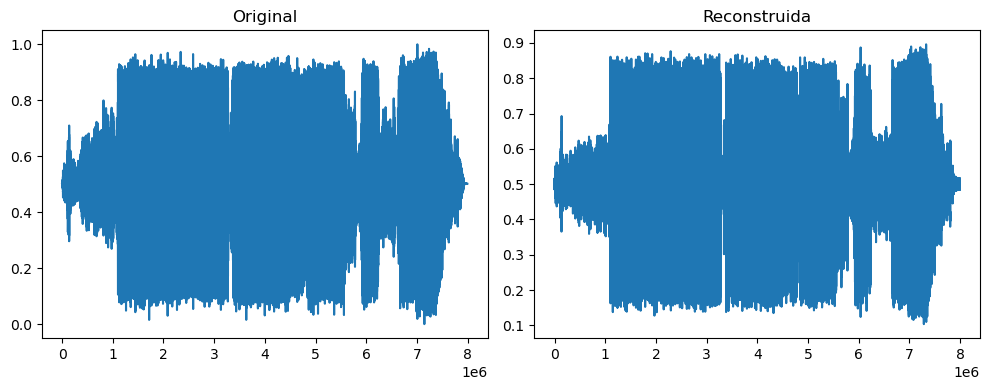

In [6]:
import numpy as np
import librosa
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

# Cargar un archivo de audio
audio_path = 'audio_muestra.mp3'
y, sr = librosa.load(audio_path, sr=None, mono=True)

# Normalizar el audio
y = (y - np.min(y)) / (np.max(y) - np.min(y))

# Dividir en bloques (ejemplo: bloques de 1024 muestras)
block_size = 1024
y_blocks = [y[i:i + block_size] for i in range(0, len(y), block_size)]
y_blocks = np.array([block for block in y_blocks if len(block) == block_size])

# Definir el autoencoder
input_layer = Input(shape=(block_size,))
encoded = Dense(128, activation='relu')(input_layer)
decoded = Dense(block_size, activation='sigmoid')(encoded)
autoencoder = Model(input_layer, decoded)

# Entrenar el autoencoder
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.fit(y_blocks, y_blocks, epochs=50, batch_size=256, shuffle=True)

# Obtener la representación comprimida y reconstruir
encoder = Model(input_layer, encoded)
encoded_blocks = encoder.predict(y_blocks)
decoded_blocks = autoencoder.predict(y_blocks)

# Reconstruir el audio
y_reconstructed = np.concatenate(decoded_blocks)

# Comparar la señal original y reconstruida
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(y[:len(y_reconstructed)])
plt.title('Original')
plt.subplot(1, 2, 2)
plt.plot(y_reconstructed)
plt.title('Reconstruida')
plt.tight_layout()
plt.show()


In [9]:
print(decoded_blocks.shape)

(7806, 1024)


In [7]:
from pydub import AudioSegment

# Convertir la señal de audio a formato de 16 bits
y_reconstructed_16bit = np.int16(y_reconstructed / np.max(np.abs(y_reconstructed)) * 32767)

# Crear un objeto AudioSegment
audio_segment = AudioSegment(
    y_reconstructed_16bit.tobytes(), 
    frame_rate=sr,
    sample_width=y_reconstructed_16bit.dtype.itemsize, 
    channels=1
)

# Exportar el audio
audio_segment.export("audio_reconstruido_fourier.wav", format="wav")

<_io.BufferedRandom name='audio_reconstruido_fourier.wav'>